# Chapitre 11 - Lab : un journal partitionné réel avec Kafka

Le cours 2 a construit un journal partitionné jouet (`st.PartitionedLog`). Ce lab refait
les mêmes expériences sur un vrai courtier, Apache Kafka 3.7 (mode KRaft, un seul nœud) :
partitions et clés, groupes de consommateurs et rééquilibrage, offsets validés et
doublons après une panne, rejeu, rétention et compaction. Le client Python est
`kafka-python-ng`.

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/streams/compose.yml -p ddia_streams up -d --wait
# ... exécuter le notebook ...
docker compose -f docker/streams/compose.yml -p ddia_streams down -v
```

Kafka écoute sur le port **11292** de l'hôte. (Le même fichier démarre aussi le
PostgreSQL du lab de capture des changements.)

**Plan.**

1. Un sujet, ses partitions et le partitionneur des clés.
2. Groupes de consommateurs et rééquilibrage.
3. Offsets validés, retard et doublons après une panne.
4. Rejouer : nouveau groupe, retour à un offset, retour à un instant.
5. Rétention : le début du journal avance.
6. Compaction : la dernière valeur de chaque clé.

In [1]:
import json
import threading
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from kafka import KafkaAdminClient, KafkaConsumer, KafkaProducer, TopicPartition
from kafka.admin import NewTopic
from kafka.errors import UnknownTopicOrPartitionError
from kafka.structs import OffsetAndMetadata

from ddia import streams as st
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
B = "localhost:11292"
admin = KafkaAdminClient(bootstrap_servers=B, client_id="lab")
print("courtier joignable ; sujets existants :", sorted(t for t in admin.list_topics() if not t.startswith("__")))


def nouveau_sujet(nom, partitions=1, **config):
    """(Re)crée un sujet vide, pour que le notebook puisse être relancé."""
    try:
        admin.delete_topics([nom])
        while nom in admin.list_topics():
            time.sleep(0.2)
        time.sleep(1.0)
    except UnknownTopicOrPartitionError:
        pass
    admin.create_topics([NewTopic(nom, partitions, 1, topic_configs={k.replace("_", "."): str(v) for k, v in config.items()})])
    time.sleep(0.5)


def producteur():
    return KafkaProducer(bootstrap_servers=B, key_serializer=lambda k: None if k is None else k.encode(),
                         value_serializer=lambda v: None if v is None else json.dumps(v).encode(), linger_ms=5)


def lire_tout(sujet, groupe=None, timeout=4.0):
    """Lit un sujet depuis le début (sans groupe : aucune trace côté courtier)."""
    c = KafkaConsumer(bootstrap_servers=B, group_id=groupe, auto_offset_reset="earliest", enable_auto_commit=False,
                      key_deserializer=lambda k: k and k.decode(), value_deserializer=lambda v: v and json.loads(v))
    parts = [TopicPartition(sujet, p) for p in c.partitions_for_topic(sujet)]
    c.assign(parts)
    c.seek_to_beginning(*parts)
    fin = c.end_offsets(parts)
    out, t0 = [], time.time()
    while time.time() - t0 < timeout and any(c.position(tp) < fin[tp] for tp in parts):
        for tp, recs in c.poll(300).items():
            out += recs
    c.close()
    return out

courtier joignable ; sujets existants : []


## 1. Un sujet, ses partitions et le partitionneur (section *Using logs for message storage*)

On crée un sujet `clics` de 6 partitions, puis on produit 6 000 messages dont la clé est
l'identifiant d'un utilisateur parmi 200. Pour chaque message, le courtier renvoie la
partition et l'offset attribués. On vérifie que la partition est exactement celle que
calcule notre implémentation du partitionneur de Kafka (`st.kafka_partition`, murmur2), que
les offsets sont contigus dans chaque partition et que l'ordre par clé est préservé.

partitions identiques à st.kafka_partition : True ; offsets contigus : True ; ordre par clé préservé à la lecture : True


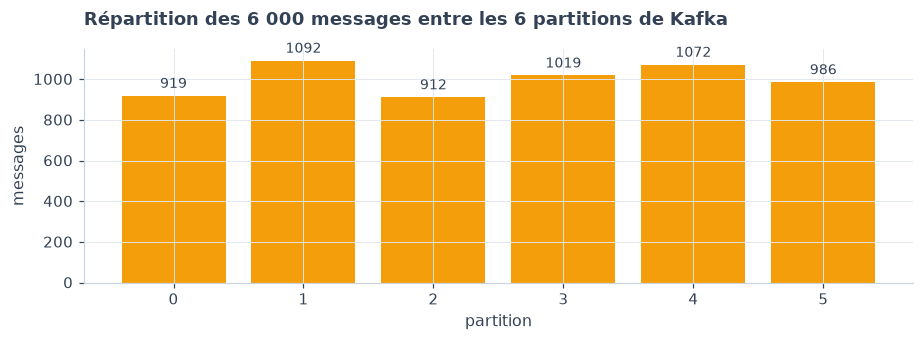

In [2]:
nouveau_sujet("clics", 6)
prod = producteur()
rng = np.random.default_rng(0)
envois = []
for i in range(6000):
    u = f"user-{int(rng.integers(0, 200))}"
    envois.append((u, i, prod.send("clics", key=u, value={"user": u, "seq": i})))
prod.flush()
meta = [(u, i, f.get().partition, f.get().offset) for u, i, f in envois]
M = pd.DataFrame(meta, columns=["clé", "seq", "partition", "offset"])
ok_part = all(p == st.kafka_partition(u, 6) for u, _, p, _ in meta)
ok_off = all(sorted(g.offset) == list(range(len(g))) for _, g in M.groupby("partition"))
recs = lire_tout("clics")
par_cle = {}
for r in recs:
    par_cle.setdefault(r.key, []).append(r.value["seq"])
ok_ordre = all(v == sorted(v) for v in par_cle.values())
print(f"partitions identiques à st.kafka_partition : {ok_part} ; offsets contigus : {ok_off} ; "
      f"ordre par clé préservé à la lecture : {ok_ordre}")
fig, ax = plt.subplots(figsize=(8.5, 3.2))
cnt = M.groupby("partition").size()
ax.bar(cnt.index, cnt.values, color=AMBER)
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("partition"); ax.set_ylabel("messages")
ax.set_title("Répartition des 6 000 messages entre les 6 partitions de Kafka")
plt.tight_layout(); plt.show()

Notre fonction de 20 lignes reproduit exactement le choix du client Java de Kafka : un
producteur dans n'importe quel langage qui hache la clé de la même façon envoie la même
clé dans la même partition, ce qui permet de garantir l'ordre par clé. La lecture à
travers les 6 partitions entrelace les clés, mais respecte l'ordre de chacune.

> **À retenir.** Kafka attribue la partition par murmur2(clé) modulo le nombre de
> partitions, et des offsets contigus dans chaque partition ; l'ordre n'est garanti qu'au
> sein d'une partition.